# YOLO for Object Detection

In [ ]:
!nvidia-smi

Mon Oct 12 15:25:57 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
# setting up the python environment
import os
HOME = os.getcwd()
print(HOME)

/content


### Install YOLOv8

YOLOv8 can be installed via pip

In [ ]:
!pip install ultralytics

from IPython import display
display.clear_output()

!yolo checks

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 42.4/112.6 GB disk)

OS                     Linux-6.6.122+-x86_64-with-glibc2.39
Environment            Colab
Python                 3.13.15
Install                pip
Path                   /usr/local/lib/python3.13/dist-packages/ultralytics
RAM                    12.67 GB
Disk                   42.4/112.6 GB
CPU                    Intel Xeon CPU @ 2.00GHz
CPU count              2
GPU                    Tesla T4, 14913MiB
GPU count              1
CUDA                   13.0

numpy                  ✅ 2.1.3>=1.23.0; platform_system != "Darwin"
numpy                  ✅ 2.1.3!=2.0.*,!=2.1.*,!=2.2.*,!=2.3.0,!=2.3.1,!=2.3.2,!=2.3.3,!=2.3.4,>=1.23.0; platform_system == "Darwin"
matplotlib             ✅ 3.10.0>=3.3.0
opencv-python          ✅ 5.0.0.93!=4.13.0.90,>=4.7.0
pillow                 ✅ 11.3.0>=7.1.2
pyyaml                 ✅ 6.0.3>=5.3.1
requests               ✅ 2.

In [ ]:
%cd {HOME}

!yolo task=detect mode=predict model=yolov8n.pt conf=0.25 source='/content/The_Death_of_Socrates.jpg'

/content
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs

image 1/1 /content/The_Death_of_Socrates.jpg: 448x640 7 persons, 1 backpack, 1 suitcase, 9.6ms
Speed: 50.3ms preprocess, 9.6ms inference, 24.5ms postprocess per image at shape (1, 3, 448, 640)
Results saved to /content/runs/detect/predict-4
💡 Learn more at https://docs.ultralytics.com/modes/predict


/content
PREDICTION BY YOLOv8


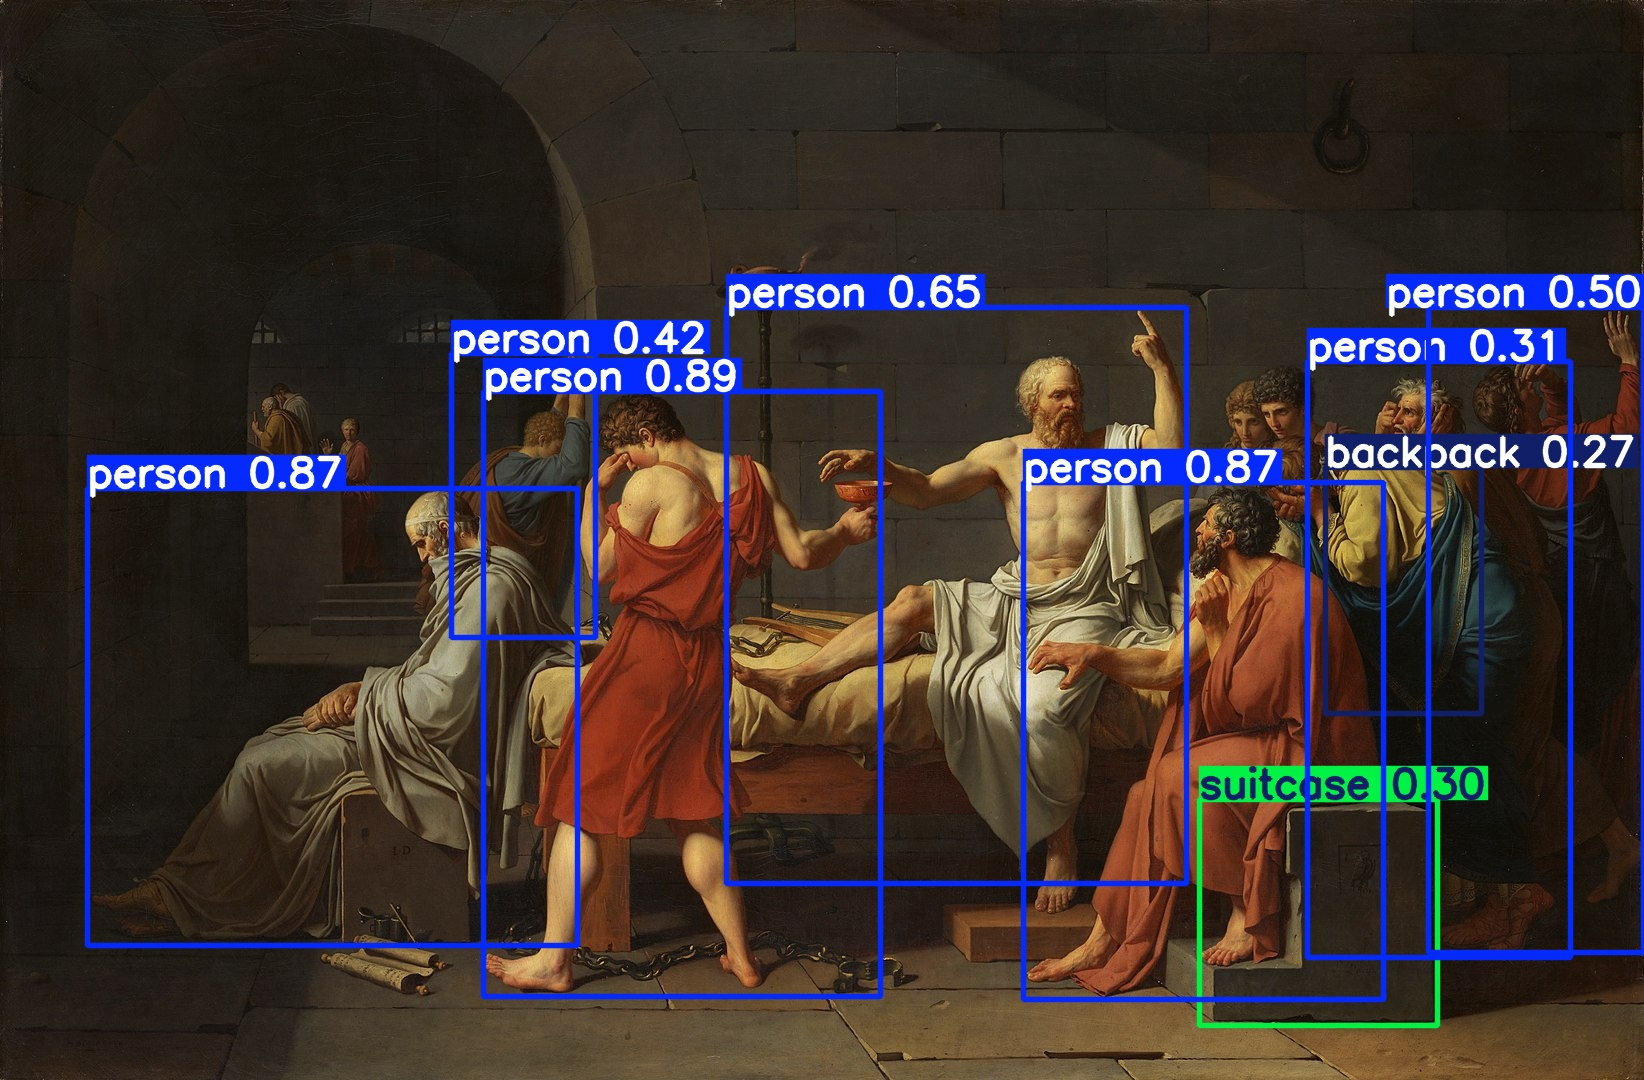

In [ ]:
from IPython.display import Image
%cd {HOME}
print("PREDICTION BY YOLOv8")
Image(filename='/content/runs/detect/predict-2/The_Death_of_Socrates.jpg', height=600)

In [ ]:
%cd {HOME}

!yolo task=detect mode=predict model=yolo26n.pt conf=0.25 source='/content/The_Death_of_Socrates.jpg'

/content
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 120 layers, 2,408,932 parameters, 0 gradients, 5.5 GFLOPs

image 1/1 /content/The_Death_of_Socrates.jpg: 448x640 8 persons, 10.7ms
Speed: 38.2ms preprocess, 10.7ms inference, 20.8ms postprocess per image at shape (1, 3, 448, 640)
Results saved to /content/runs/detect/predict-3
💡 Learn more at https://docs.ultralytics.com/modes/predict


/content
PREDICTION BY YOLO26


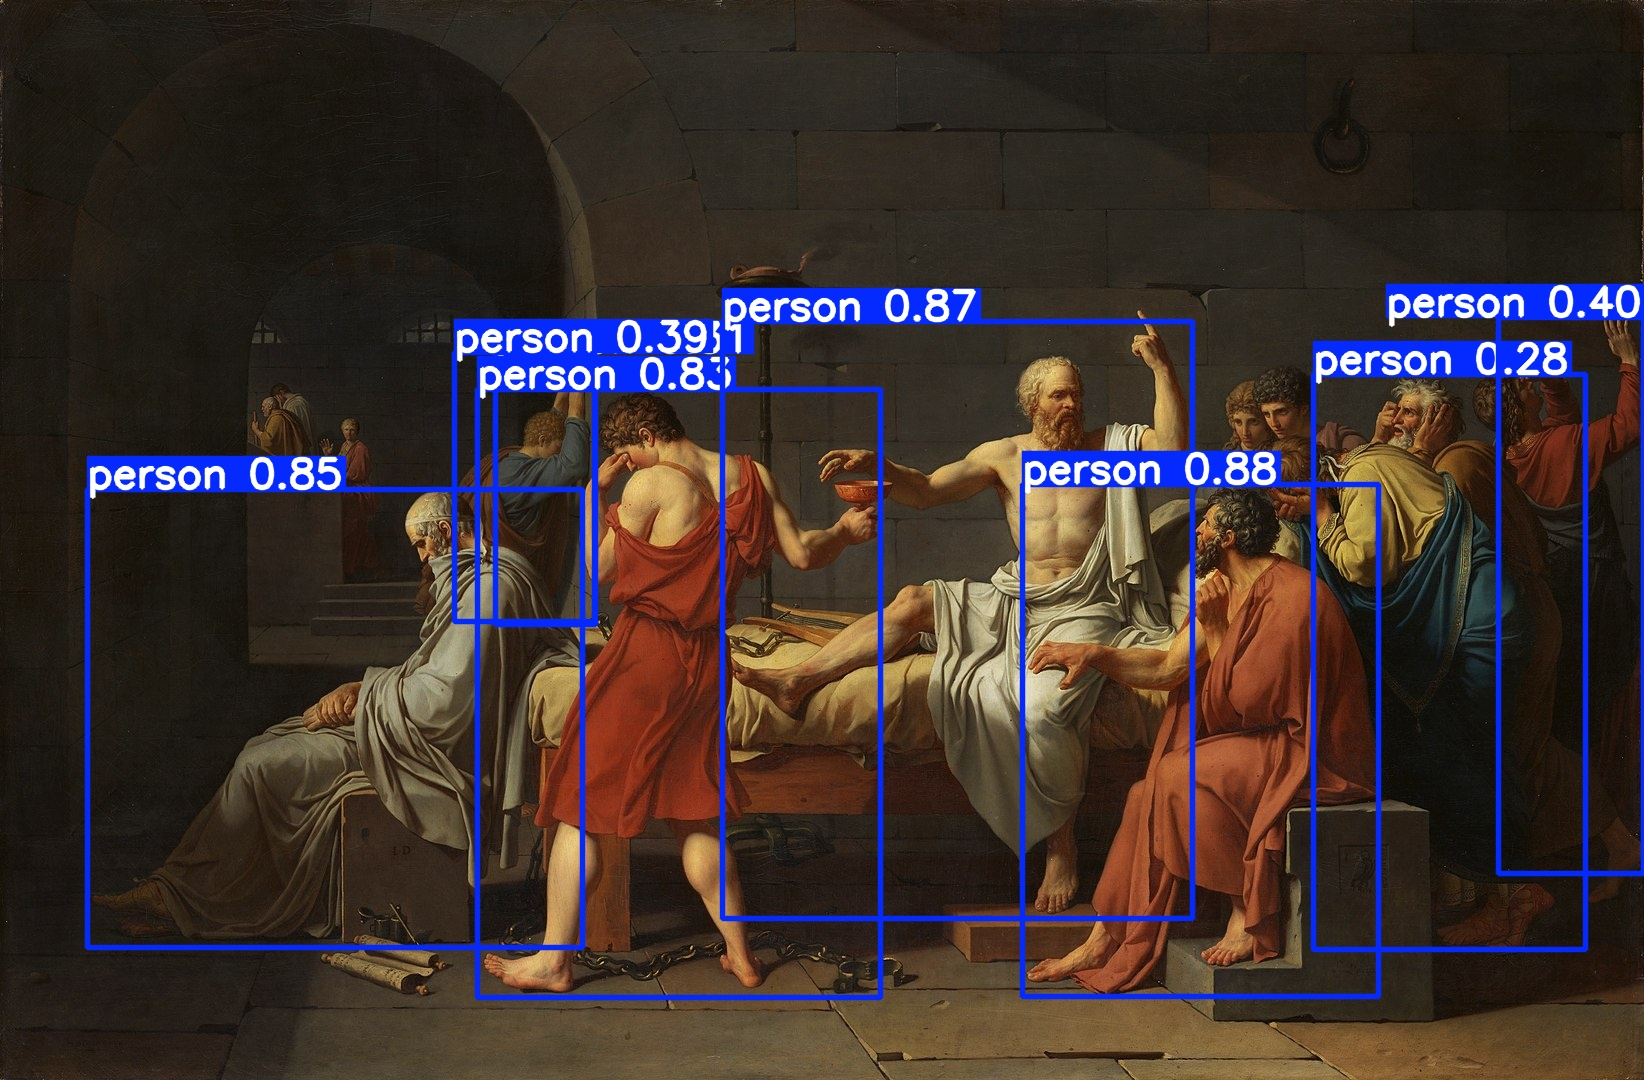

In [ ]:
%cd {HOME}
print("PREDICTION BY YOLO26")
Image(filename='/content/runs/detect/predict-3/The_Death_of_Socrates.jpg', height=600)

## HOW YOLO WORKS?

### You Only Look Once: Entire image is processed in one step.

* The input image is divided into a `S x S` grid.
* Each grid cell predicts `B` bounding boxes and confidence score for those boxes.
* A single CNN predicts the bounding boxes and class probability for those boxes.
* Confidence = $P(\text{object}) \times \text{IoU}_{\text{pred}}^{\text{truth}}$
* Each bounding box contains five predictions – $x, y, h, w$ and confidence.
* Each grid cell also predicts $C$ conditional class probability, $ P(Class_i|Object) $
* Initial convolutional layers extract features and final fully connected layers predict the output probabilities and coordinates.
* The error is `sum-squared error` parameterized to increase the loss from bounding box coordinate predictions and decrease the loss from confidence predictions for boxes that don't contain objects.


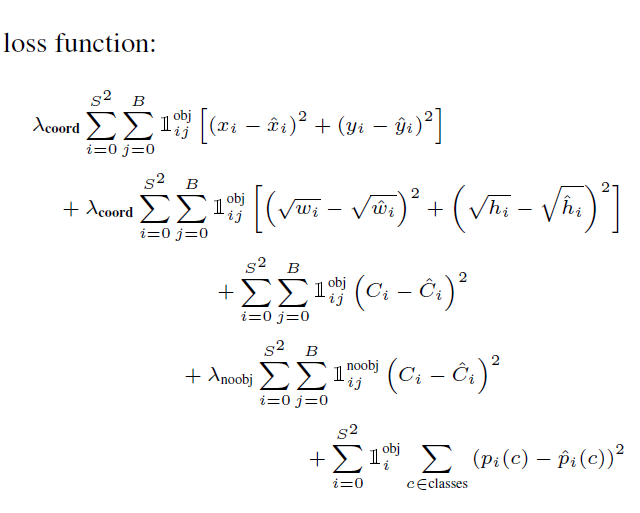

### YOLO architecture

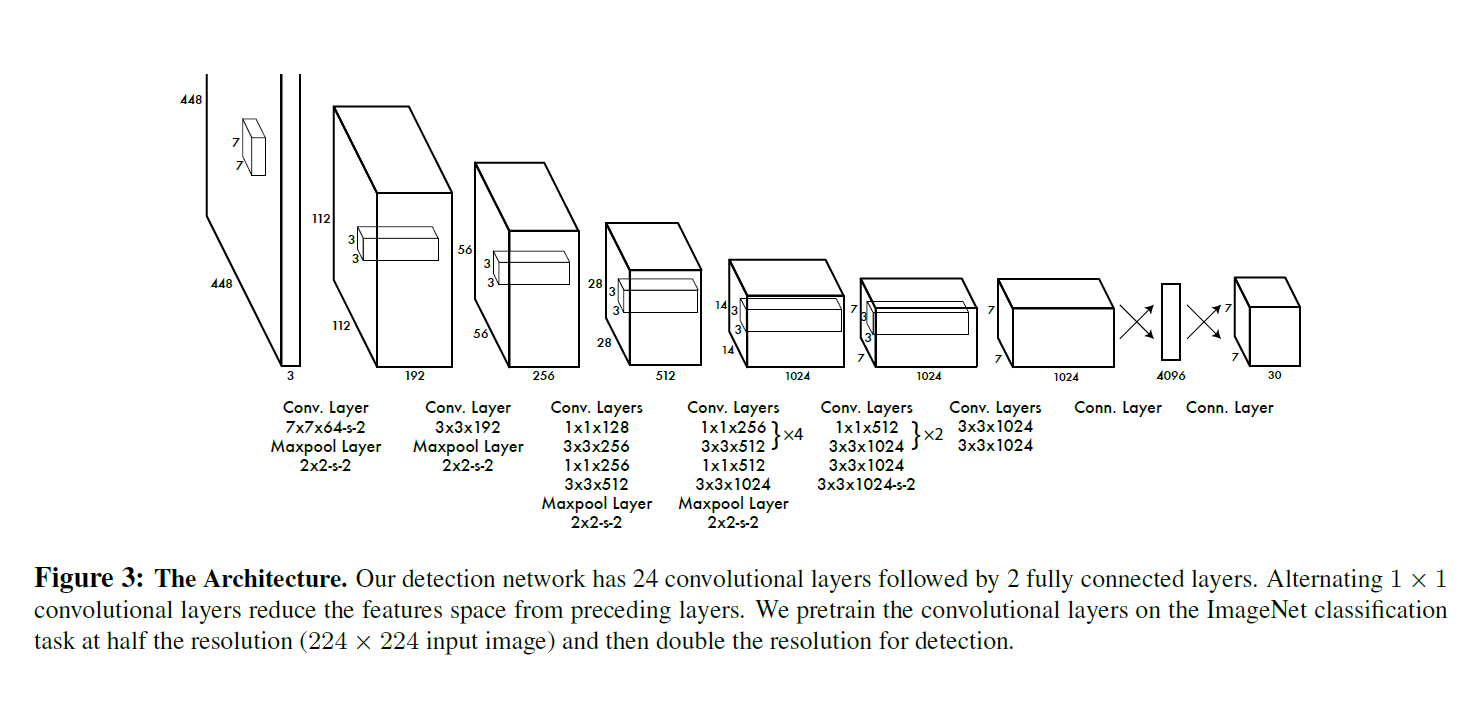

# YOLO for Object Detection


## Model lineage

| Model / year | Lineage / team | Backbone | Neck / feature fusion | Detection head / box prediction | Significant innovations |
|---|---|---|---|---|---|
| **YOLOv1** (2016) | Redmon et al. | Custom 24-convolutional-layer CNN, partly inspired by GoogLeNet; 1×1 channel-reduction and 3×3 convolutions; Leaky ReLU | No modern dedicated FPN/PAN neck | Grid-based predictions; each cell predicts box coordinates, confidence and class probabilities; fully connected layers produce the final predictions | Single-stage detection in one forward pass; 448×448 input and 7×7 grid in the original design; no BatchNorm; dropout after the first fully connected layer |
| **YOLOv2 / YOLO9000** (2017) | Redmon & Farhadi | Darknet-19; BatchNorm throughout | Passthrough layer fuses fine-grained higher-resolution features | Anchor-box-based convolutional prediction; predicts offsets relative to anchor priors | Dimension-clustered anchors; multi-scale training; higher-resolution classifier pretraining; joint detection/classification training in YOLO9000 |
| **YOLOv3** (2018) | Redmon & Farhadi | Darknet-53 with residual connections | FPN-style top-down feature fusion; predictions at three scales | Anchor-based; three detection heads; independent logistic class classifiers | Better multi-scale detection, especially for small objects; deeper residual backbone |
| **YOLOv4** (2020) | Bochkovskiy et al.; Darknet lineage reference design | CSPDarknet53; CSP connections; Mish | SPP and PANet | Anchor-based YOLOv3-style head | Mosaic augmentation, CIoU loss, DropBlock, self-adversarial training and other "bag of freebies / bag of specials" improvements |
| **Scaled-YOLOv4** (2020) | WongKinYiu / YOLOv4 research line | CSP-based architectures scaled in depth, width and resolution | Scaled CSP-PAN-style aggregation, depending on variant | Retains the YOLO detection approach while scaling capacity | An important model-scaling study rather than another universal YOLO generation |
| **YOLOv5** (2020 onward) | Ultralytics; independent implementation lineage | PyTorch implementation; CSP-derived C3 blocks; early versions used Focus, later designs changed; depth/width scaling | FPN/PAN-style fusion; SPPF in common versions | Original versions: anchor-based multi-scale prediction heads | AutoAnchor, Mosaic augmentation, accessible training/export tooling; architecture and defaults evolved across releases |
| **PP-YOLO / PP-YOLOE / PP-YOLOE+** (2020–2022) | PaddlePaddle / Baidu; parallel branch | ResNet / CSPResNet-style feature extractors, depending on version | FPN/PAN-family multi-scale fusion | PP-YOLOE: anchor-free, decoupled head and task-aligned label assignment | Independent YOLO-inspired branch; not a direct numbered successor to YOLOv5 |
| **YOLOX** (2021) | Megvii; independent branch | CSPDarknet-style backbone; commonly includes SPP | PAN-style feature pyramid | Anchor-free, decoupled classification/regression head; SimOTA assignment | Removes anchor design; conventional inference often still uses NMS |
| **YOLOv6** (2022; v3.0 in 2023) | Meituan | EfficientRep / re-parameterised convolution design | Rep-PAN and related efficient multi-scale fusion | Efficient decoupled head; later versions use anchor-free prediction, with anchor-assisted training in some configurations | Hardware-aware deployment, quantisation focus, structural re-parameterisation (training branches fuse for inference) |
| **YOLOv7** (2022) | WongKinYiu et al.; independent branch | E-ELAN (Extended Efficient Layer Aggregation Network); re-parameterised convolution modules | SPPCSPC and PAN-style aggregation | Anchor-based, multi-scale head | Trainable bag-of-freebies; auxiliary head / deep supervision during training; gradient-path and re-parameterisation design |
| **YOLOv8** (2023) | Ultralytics | C2f CSP-style blocks and SPPF | FPN/PAN-style multi-scale fusion | Anchor-free, decoupled head; Distribution Focal Loss (DFL) for box regression | Model family covers detection, instance segmentation, classification, pose and oriented bounding boxes (OBB) |
| **YOLOv9** (2024) | Wang et al.; independent branch | GELAN (Generalized Efficient Layer Aggregation Network) | Multi-scale feature aggregation, commonly integrated with GELAN | Original implementation is anchor-based | PGI (Programmable Gradient Information) preserves useful gradient/information flow; GELAN targets efficient feature aggregation |
| **YOLOv10** (2024) | Tsinghua University; independent design | Efficiency-oriented backbone with SCDown and C2f-style blocks | PAN/FPN-style multi-scale fusion with efficiency-focused components | Consistent dual assignments during training (one-to-many and one-to-one); supports NMS-free end-to-end inference | Designed jointly for accuracy and latency; removes conventional NMS from its end-to-end inference path |
| **YOLO11** (2024) | Ultralytics | C3k2 blocks, SPPF and C2PSA attention | FPN/PAN-style fusion; C3k2 blocks also appear in neck stages | Anchor-free, decoupled head; DFL-based box regression in standard detection configurations | Improved accuracy/compute trade-off; supports detection, segmentation, pose, classification and OBB |
| **YOLO12** (2025 community/research release) | Community / independent | Attention-centric designs, including area-attention concepts; exact implementation varies | Multi-scale feature fusion | Depends on the specific repository and configuration | Treat as a distinct community/research release; verify repository, weights and task support rather than assuming one official successor |
| **YOLO26** (2026) | Ultralytics | C3k2-family backbone, SPPF with shortcut, C2PSA attention | FPN/PAN-style multi-scale fusion | Anchor-free, decoupled prediction; end-to-end one-to-one head supports NMS-free inference; DFL removed (`reg_max=1`) for direct box regression | Uses the MuSGD optimizer; targets efficient edge/CPU deployment; family includes detection and other dense-prediction tasks |
| **YOLO-World** (2024 onward) | Open-vocabulary YOLO branch | YOLO-style visual backbone combined with vision-language / text components | YOLO-style multi-scale feature pipeline | Open-vocabulary detection: categories specified through text prompts rather than a fixed closed set | Extends YOLO toward language-guided detection; differs from standard fixed-class YOLO checkpoints |
| **YOLOE / YOLOE-26 family** (2025 onward) | Ultralytics open-vocabulary branch | YOLO-style backbone with promptable / open-vocabulary components | Multi-scale features for detection and segmentation | Supports text prompts, visual prompts and/or prompt-free prediction depending on variant | Capability-focused branch, not simply the next numbered conventional detector; check the specific variant's documentation |

---

## Cross-generation comparison

| Feature | Early generations | Middle generations | Modern examples |
|---|---|---|---|
| **Backbone** | Custom CNN → Darknet-19 → Darknet-53 | CSPDarknet, E-ELAN, GELAN | C3, C2f, C3k2 and attention-augmented designs |
| **Feature fusion** | Minimal dedicated neck in v1 | FPN, PAN, SPP/SPPF, CSP-based aggregation | FPN/PAN still common, with more efficient blocks and attention |
| **Anchors** | Grid-based predictions in v1; anchors introduced in v2 | Anchor-based for v2–v7 | Anchor-free in YOLOX, YOLOv8, YOLO11 and YOLO26; implementations differ by branch |
| **Prediction head** | Grid output plus fully connected layers | Convolutional multi-scale heads | Decoupled heads; some versions use one-to-one end-to-end prediction |
| **NMS** | Post-processing | Standard in most conventional detectors | YOLOv10 and YOLO26 provide NMS-free end-to-end paths |
| **Training advances** | Box, confidence and classification losses | Better assignment, augmentation, IoU losses, auxiliary heads | DFL, task-aligned assignment, PGI, dual assignment and newer optimizers |
| **Tasks** | Object detection | Primarily detection | Detection, instance segmentation, pose, OBB, classification and open-vocabulary tasks |

---

## Caveats

- **YOLOv1 was not simply GoogLeNet.** It was a custom CNN, partly inspired by GoogLeNet's use of 1×1 and 3×3 convolutions.
- **The YOLO family has multiple independent lineages.** YOLOv4, YOLOv5, YOLOX, YOLOv6, YOLOv7, YOLOv9 and YOLOv10 came from different teams; they are not sequential edits to a single codebase.
- **Version labels can hide differences.** Ultralytics YOLOv3u / YOLOv5u use anchor-free heads, unlike the original historical YOLOv3 / YOLOv5 designs.
- **Details vary by model size and task.** The n/s/m/l/x variants, segmentation models and pose models may use different heads.
- **2026 status is time-sensitive.** Check the official docs and repositories for current checkpoints and supported tasks.

---

## References

| Paper | Link |
|---|---|
| YOLOv1 — You Only Look Once: Unified, Real-Time Object Detection | https://arxiv.org/abs/1506.02640 |
| YOLOv2 — YOLO9000: Better, Faster, Stronger | https://arxiv.org/abs/1612.08242 |
| YOLOv3 — An Incremental Improvement | https://arxiv.org/abs/1804.02767 |
| YOLOv4 — Optimal Speed and Accuracy of Object Detection | https://arxiv.org/abs/2004.10934 |
| YOLOX — Exceeding YOLO Series in 2021 | https://arxiv.org/abs/2107.08430 |
| YOLOv7 — Trainable Bag-of-Freebies Sets New State-of-the-Art | https://arxiv.org/abs/2207.02696 |
| YOLOv9 — Learning What You Want to Learn Using Programmable Gradient Information | https://arxiv.org/abs/2402.13616 |
| YOLOv10 — Real-Time End-to-End Object Detection | https://arxiv.org/abs/2405.14458 |

**Documentation**

- Ultralytics architecture guide — https://docs.ultralytics.com/guides/yolo-architecture
- Ultralytics models — https://docs.ultralytics.com/models
- YOLO11 docs — https://docs.ultralytics.com/models/yolo11/
- YOLO26 docs — https://docs.ultralytics.com/models/yolo26/

### YOLO Architecture

In [ ]:
import torch
import torch.nn as nn

In [ ]:
class YOLO(nn.Module):
  def __init__(self, in_channels=3, padding=1, dropout=0.5, **kwargs) -> None:
    super(YOLO, self).__init__()
    self.net = nn.Sequential(
        # first
        nn.Conv2d(in_channels, 64, kernel_size=7, stride=2),
        nn.LeakyReLU(0.1),
        nn.MaxPool2d(kernel_size=2),

        # second
        nn.Conv2d(in_channels=64, out_channels=192, kernel_size=3, padding=1),
        nn.LeakyReLU(0.1),
        nn.MaxPool2d(kernel_size=2),

        # third (group of layers)
        nn.Conv2d(in_channels=192, out_channels=128, kernel_size=1),
        nn.LeakyReLU(0.1),
        nn.Conv2d(in_channels=128, out_channels=256, kernel_size=3, padding=1,),
        nn.LeakyReLU(0.1),
        nn.Conv2d(in_channels=256, out_channels=256, kernel_size=1),
        nn.LeakyReLU(0.1),
        nn.Conv2d(in_channels=256, out_channels=512, kernel_size=3, padding=1),
        nn.MaxPool2d(kernel_size=2),

        # fourth (group of layers)
        nn.Conv2d(in_channels=512, out_channels=256, kernel_size=1),
        nn.LeakyReLU(0.1),
        nn.Conv2d(in_channels=256, out_channels=512, kernel_size=3, padding=1),
        nn.LeakyReLU(0.1),
        nn.Conv2d(in_channels=512, out_channels=256, kernel_size=1),
        nn.LeakyReLU(0.1),
        nn.Conv2d(in_channels=256, out_channels=512, kernel_size=3, padding=1),
        nn.LeakyReLU(0.1),
        nn.Conv2d(in_channels=512, out_channels=256, kernel_size=1),
        nn.LeakyReLU(0.1),
        nn.Conv2d(in_channels=256, out_channels=512, kernel_size=3, padding=1),
        nn.LeakyReLU(0.1),
        nn.Conv2d(in_channels=512, out_channels=256, kernel_size=1),
        nn.LeakyReLU(0.1),
        nn.Conv2d(in_channels=256, out_channels=512, kernel_size=3, padding=1),
        nn.LeakyReLU(0.1),
        nn.Conv2d(in_channels=512, out_channels=1024, kernel_size=3, padding=1),
        nn.LeakyReLU(0.1),
        nn.MaxPool2d(kernel_size=2),

        # fifth (group of layers)
        nn.Conv2d(in_channels = 1024, out_channels=512, kernel_size=1),
        nn.LeakyReLU(0.1),
        nn.Conv2d(in_channels=512, out_channels=1024, kernel_size=3, padding=1),
        nn.LeakyReLU(0.1),
        nn.Conv2d(in_channels = 1024, out_channels=512, kernel_size=1),
        nn.LeakyReLU(0.1),
        nn.Conv2d(in_channels=512, out_channels=1024, kernel_size=3, padding=1),
        nn.LeakyReLU(0.1),
        nn.Conv2d(in_channels = 1024, out_channels=1024, kernel_size=3, padding=1, stride = 2),

        # sixth
        nn.Conv2d(in_channels = 1024, out_channels = 1024, kernel_size=3, padding=1),
        nn.LeakyReLU(0.1),
        nn.Conv2d(in_channels = 1024, out_channels = 1024, kernel_size=3, padding=1),
        nn.LeakyReLU(0.1),

        # seventh (connected layer 1)
        nn.Flatten(),
        nn.Linear(in_features=50176, out_features=4096),
        nn.LeakyReLU(0.1),
        nn.Dropout(dropout),
        nn.Linear(in_features=4096, out_features = 1470)
    )

  def forward(self, x:torch.Tensor) -> torch.Tensor:
    return self.net(x)

### YOLO Implementation

The model implemented here is taken from pre-trained YOLOv8 to perform object detection.

In [1]:
!pip install ultralytics

from ultralytics import YOLO

model = YOLO("yolov8n.pt")
model.train(data='coco128.yaml', epochs=10, imgsz=640)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 12.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.2/97.2 kB 4.6 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.178 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=F

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 11, 13, 14, 15, 16, 17, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 38, 39, 40, 41, 42, 43, 44, 45, 46, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 67, 68, 69, 71, 72, 73, 74, 75, 76, 77, 79])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7ea7c2335e50>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,


image 1/1 /content/Totoro.jpg: 384x640 5 persons, 1 clock, 110.2ms
Speed: 3.7ms preprocess, 110.2ms inference, 1.1ms postprocess per image at shape (1, 3, 384, 640)


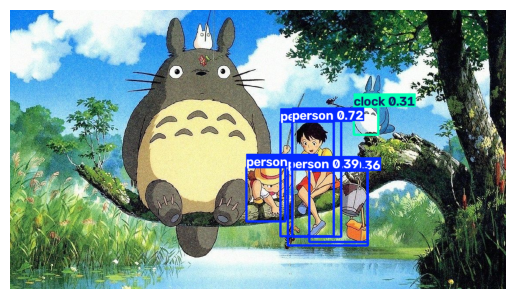

In [14]:
import matplotlib.pyplot as plt


model = YOLO('/content/runs/detect/train/weights/best.pt')
results = model("/content/Totoro.jpg", conf=0.25)

annotated_img = results[0].plot()

plt.imshow(annotated_img[:, :, ::-1])
plt.axis('off')
plt.show()


image 1/1 /content/Totoro.jpg: 384x640 1 person, 101.6ms
Speed: 3.7ms preprocess, 101.6ms inference, 1.0ms postprocess per image at shape (1, 3, 384, 640)


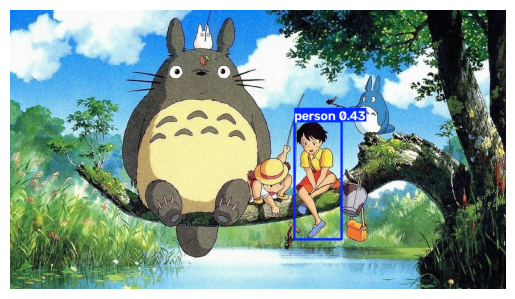

In [15]:
model = YOLO("yolo26n.pt")
results = model("/content/Totoro.jpg", conf=0.25)

annotated_img = results[0].plot()

plt.imshow(annotated_img[:, :, ::-1])
plt.axis('off')
plt.show()

## Observation

YOLO26 is far better than YOLO_v8. Why?

The main reasons
- Better feature extraction and detection heads: YOLO26 improves how features are converted into bounding boxes and class predictions.
- NMS-free inference: It can produce final detections without the traditional Non-Maximum Suppression step, reducing post-processing overhead.
- Better training recipe: MuSGD, Progressive Loss and STAL improve optimisation and help with small-object detection.
- Task-specific improvements: Its segmentation architecture and losses are updated too, rather than relying only on detection improvements.

## Next

The next project will be training a YOLO for brain tumour segementation.